# Experiment 2: Exploratory Data Analysis (EDA), Descriptive Statistics, and Data Visualization

**Aim:** To perform Exploratory Data Analysis (EDA), descriptive statistical analysis, and data visualization on the Titanic dataset using Python.

**Mapped CO(s):** CO1, CO2

## 1. Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## 2. Load the Titanic Dataset

In [2]:
df = sns.load_dataset("titanic")

print("Dataset loaded successfully")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully
Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 3. Explore Dataset Structure

In [3]:
print("Column names:")
print(df.columns.tolist())
print("\nDataset info:")
df.info()

Column names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    


In [4]:
print("Data types:")
print(df.dtypes)
print("\nFirst 5 records:")
df.head()

Data types:
survived          int64
pclass            int64
sex                 str
age             float64
sibsp             int64
parch             int64
fare            float64
embarked            str
class          category
who                 str
adult_male         bool
deck           category
embark_town         str
alive               str
alone              bool
dtype: object

First 5 records:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 4. Missing Values

In [5]:
missing = df.isna().sum()
missing_pct = (df.isna().mean() * 100).round(2)

missing_df = pd.DataFrame({
    "Missing Count": missing,
    "Missing %": missing_pct
})
print("Missing values per column:")
missing_df[missing_df["Missing Count"] > 0].sort_values("Missing Count", ascending=False)

Missing values per column:


,Missing Count,Missing %
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22


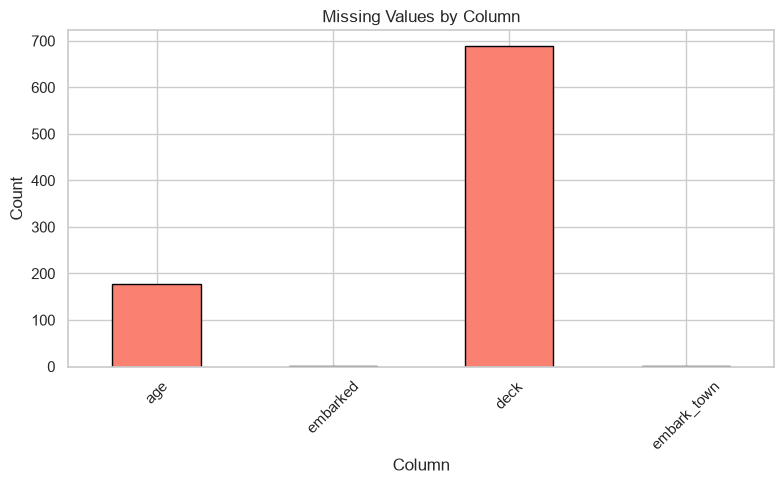

In [6]:
missing_df[missing_df["Missing Count"] > 0]["Missing Count"].plot(
    kind="bar", color="salmon", edgecolor="black"
)
plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Descriptive Statistics

In [7]:
print("Descriptive statistics for numerical variables:")
df.describe()

Descriptive statistics for numerical variables:


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
print("Descriptive statistics for categorical variables:")
df.describe(include=["object", "bool", "category"])

Descriptive statistics for categorical variables:


/var/folders/9l/rs7bfxps4jd0jsfdd_hrzvjr0000gn/T/ipykernel_8283/2560903613.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=["object", "bool", "category"])


,sex,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891,889,891,891,891,203,889,891,891
unique,2,3,3,3,2,7,3,2,2
top,male,S,Third,man,True,C,Southampton,no,True
freq,577,644,491,537,537,59,644,549,537


## 6. Visualize Categorical Variables (Bar Charts)

/var/folders/9l/rs7bfxps4jd0jsfdd_hrzvjr0000gn/T/ipykernel_8283/3816371508.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="sex", ax=axes[0], palette="Set2")
/var/folders/9l/rs7bfxps4jd0jsfdd_hrzvjr0000gn/T/ipykernel_8283/3816371508.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="class", ax=axes[1], palette="Set2",
/var/folders/9l/rs7bfxps4jd0jsfdd_hrzvjr0000gn/T/ipykernel_8283/3816371508.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="survived", ax=axes[2], palette="Set2")


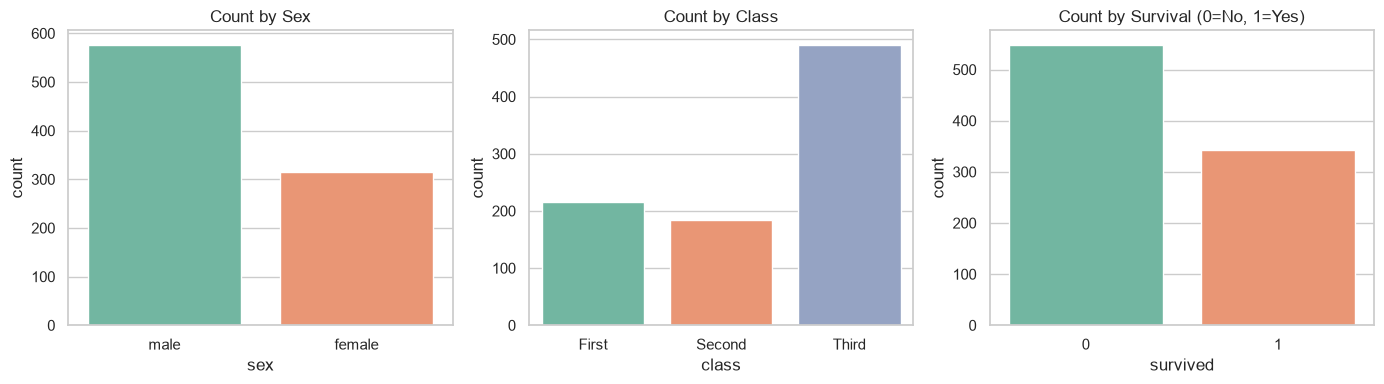

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.countplot(data=df, x="sex", ax=axes[0], palette="Set2")
axes[0].set_title("Count by Sex")

sns.countplot(data=df, x="class", ax=axes[1], palette="Set2",
              order=["First", "Second", "Third"])
axes[1].set_title("Count by Class")

sns.countplot(data=df, x="survived", ax=axes[2], palette="Set2")
axes[2].set_title("Count by Survival (0=No, 1=Yes)")

plt.tight_layout()
plt.show()

## 7. Visualize Numerical Variables (Histograms & Box Plots)

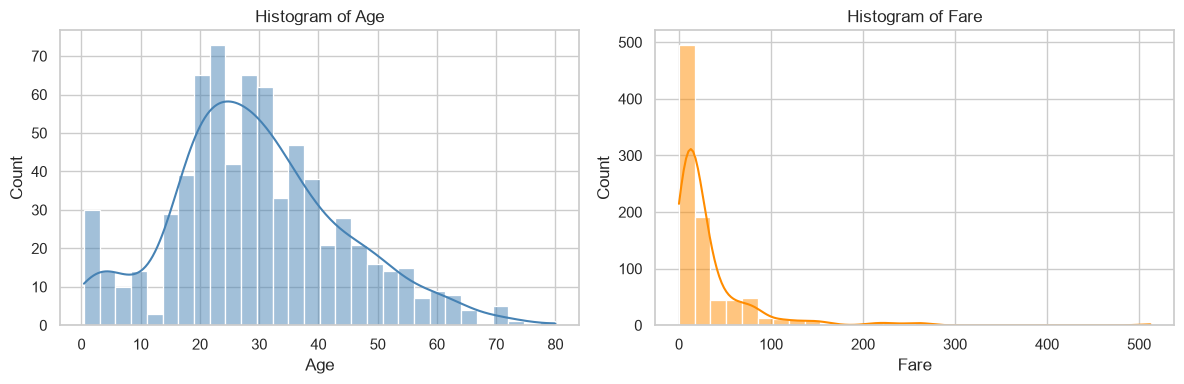

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["age"].dropna(), bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Histogram of Age")
axes[0].set_xlabel("Age")

sns.histplot(df["fare"], bins=30, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("Histogram of Fare")
axes[1].set_xlabel("Fare")

plt.tight_layout()
plt.show()

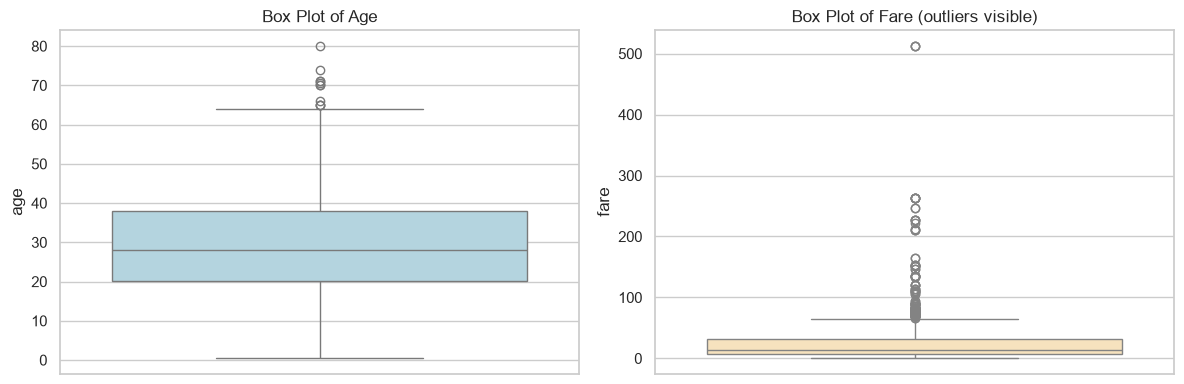

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(y=df["age"], ax=axes[0], color="lightblue")
axes[0].set_title("Box Plot of Age")

sns.boxplot(y=df["fare"], ax=axes[1], color="moccasin")
axes[1].set_title("Box Plot of Fare (outliers visible)")

plt.tight_layout()
plt.show()

## 8. Scatter Plot

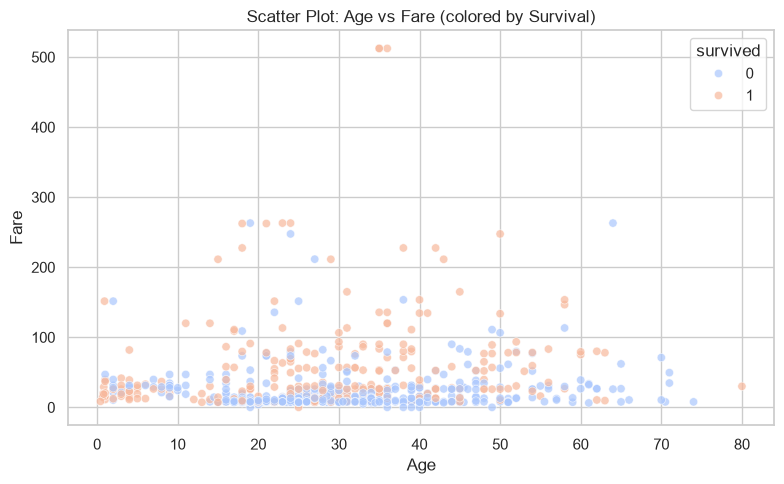

In [12]:
sns.scatterplot(data=df, x="age", y="fare", hue="survived", alpha=0.7, palette="coolwarm")
plt.title("Scatter Plot: Age vs Fare (colored by Survival)")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()

## 9. Correlation Heatmap

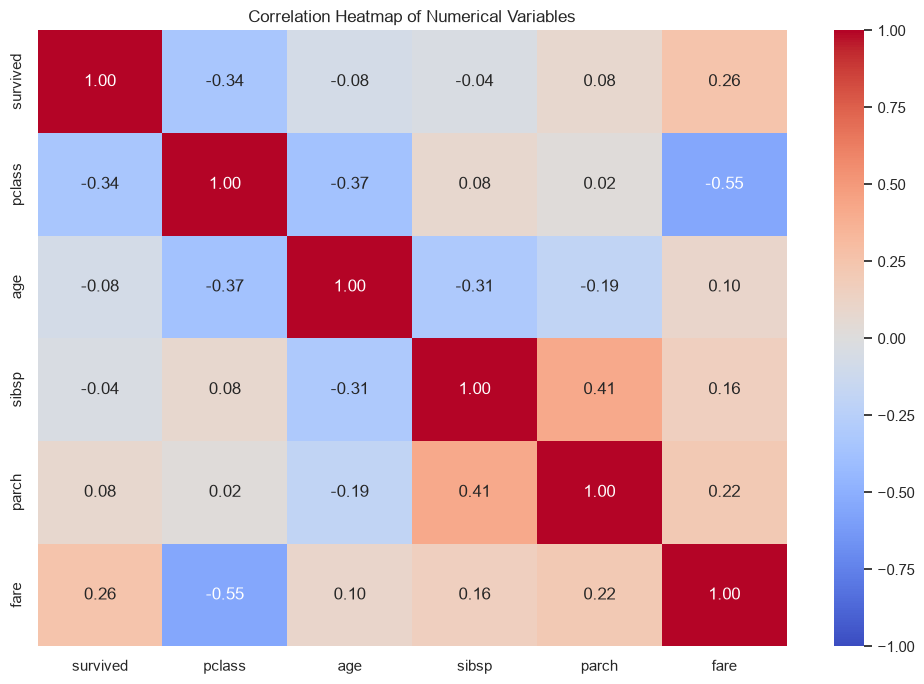

In [13]:
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

---
## Exercises / Assignments

### Exercise 1: Descriptive statistics for Fare

In [14]:
print("Descriptive statistics for Fare:")
print(df["fare"].describe())
print(f"\nMedian: {df['fare'].median():.2f}")
print(f"Mode: {df['fare'].mode().iloc[0]:.2f}")
print(f"Variance: {df['fare'].var():.2f}")

Descriptive statistics for Fare:
count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: fare, dtype: float64

Median: 14.45
Mode: 8.05
Variance: 2469.44


### Exercise 2: Histogram of Age

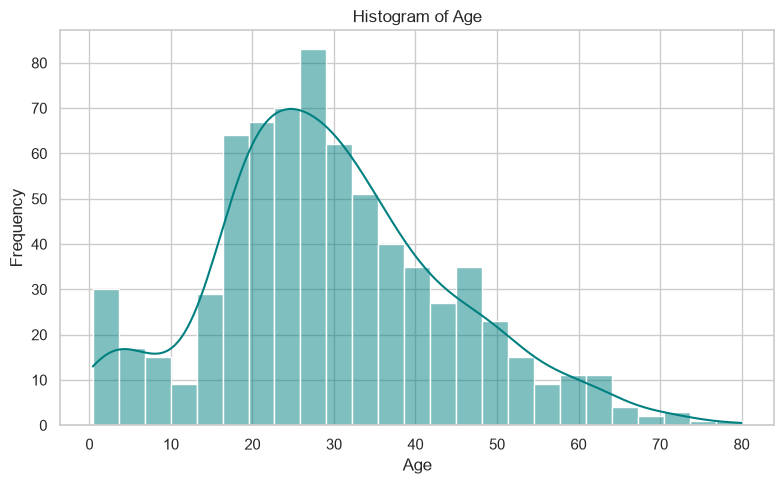

In [15]:
sns.histplot(df["age"].dropna(), bins=25, kde=True, color="teal")
plt.title("Histogram of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Exercise 3: Box plot for Fare (identify outliers)

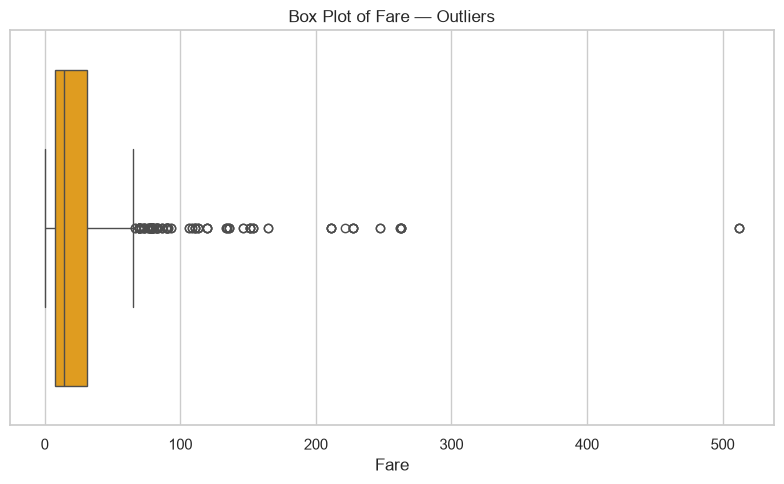

IQR = 23.09, Upper fence = 65.63
Number of Fare outliers (above upper fence): 116


In [16]:
sns.boxplot(x=df["fare"], color="orange")
plt.title("Box Plot of Fare — Outliers")
plt.xlabel("Fare")
plt.tight_layout()
plt.show()

Q1 = df["fare"].quantile(0.25)
Q3 = df["fare"].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
n_outliers = (df["fare"] > upper).sum()
print(f"IQR = {IQR:.2f}, Upper fence = {upper:.2f}")
print(f"Number of Fare outliers (above upper fence): {n_outliers}")

### Exercise 4: Heatmap of correlation between numerical variables

(Already generated in Section 9 above.)

### Exercise 5: Interpret one visualization

**Interpretation of the Fare box plot:** The Fare distribution is right-skewed with many high-value outliers. Most passengers paid relatively low fares (median is much lower than the mean), while a smaller group of first-class passengers paid very expensive tickets — these appear as points above the upper whisker.

---
## Observation

- The Titanic dataset was successfully loaded and explored.
- Descriptive statistics summarized the numerical features of the dataset.
- Missing values were identified in some columns (notably `age`, `deck`, and `embark_town`/`embarked`).
- Histograms showed the distribution of Age and Fare.
- Box plots helped identify outliers (especially in Fare).
- Heatmaps displayed the correlation among numerical variables.
- Data visualizations made it easier to understand passenger characteristics and survival patterns.

## Result

Exploratory Data Analysis, descriptive statistical analysis, and data visualization were successfully performed using Python. The analysis provided useful insights into the Titanic dataset and demonstrated the importance of visualizing data before further analysis.

## Conclusion

The experiment demonstrated the use of Python libraries for performing Exploratory Data Analysis (EDA), descriptive statistics, and data visualization. Various statistical measures and graphical techniques helped understand the structure, distribution, and relationships within the Titanic dataset. EDA serves as an essential step in the data science process by improving data understanding and supporting informed decision-making.